<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Finding Outliers**


Estimated time needed: **30** minutes


In this lab, you will work with a cleaned dataset to perform exploratory data analysis or EDA. 
You will explore the distribution of key variables and focus on identifying outliers in this lab.


## Objectives


In this lab, you will perform the following:


-  Analyze the distribution of key variables in the dataset.

-  Identify and remove outliers using statistical methods.

-  Perform relevant statistical and correlation analysis.


#### Install and import the required libraries


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

<h3>Step 1: Load and Explore the Dataset</h3>


Load the dataset into a DataFrame and examine the structure of the data.


In [2]:
file_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv"

#Create the dataframe
df = pd.read_csv(file_url)

#Display the top 10 records
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


<h3>Step 2: Plot the Distribution of Industry</h3>


Explore how respondents are distributed across different industries.

- Plot a bar chart to visualize the distribution of respondents by industry.

- Highlight any notable trends.


<StringArray>
[                                         nan,
                                 'Healthcare',
                       'Software Development',
                 'Banking/Financial Services',
                                     'Other:',
               'Media & Advertising Services',
                                  'Insurance',
 'Internet, Telecomm or Information Services',
                           'Higher Education',
                                     'Energy',
                                    'Fintech',
               'Retail and Consumer Services',
                              'Manufacturing',
                                 'Government',
       'Computer Systems Design and Services',
            'Transportation, or Supply Chain']
Length: 16, dtype: str


Text(0.5, 1.0, 'Distribution of tech industries')

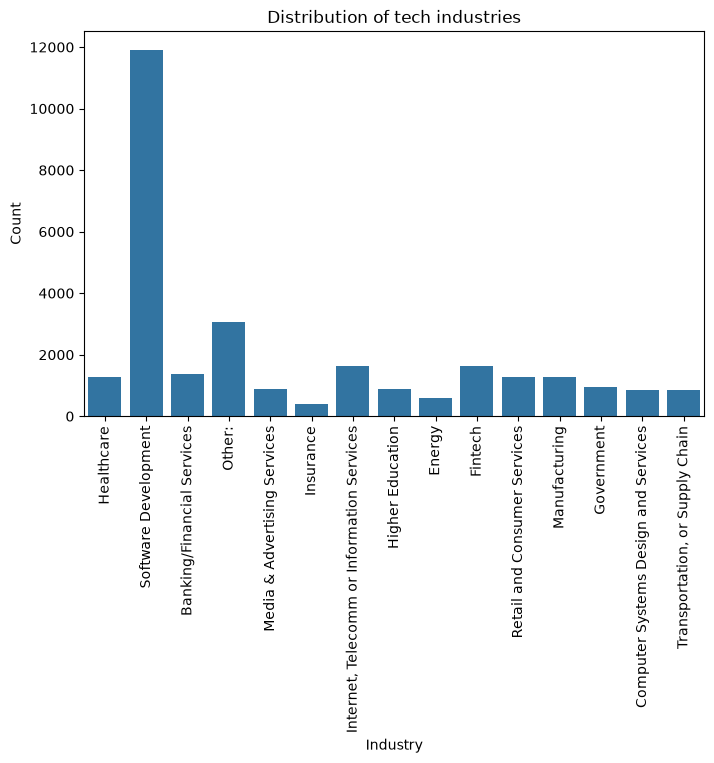

In [17]:
print(df["Industry"].unique())

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Industry")
plt.xticks(rotation=90)
plt.ylabel("Count")
plt.title("Distribution of tech industries")

In [ ]:
# Notable trends:
# - Most popular industry is software development, followed by "other"

<h3>Step 3: Identify High Compensation Outliers</h3>


Identify respondents with extremely high yearly compensation.

- Calculate basic statistics (mean, median, and standard deviation) for `ConvertedCompYearly`.

- Identify compensation values exceeding a defined threshold (e.g., 3 standard deviations above the mean).


In [20]:
print(df["ConvertedCompYearly"].dtypes)

df["ConvertedCompYearly"].describe()

float64


count    2.343500e+04
mean     8.615529e+04
std      1.867570e+05
min      1.000000e+00
25%      3.271200e+04
50%      6.500000e+04
75%      1.079715e+05
max      1.625660e+07
Name: ConvertedCompYearly, dtype: float64

In [32]:
mean_comp = df["ConvertedCompYearly"].mean()
median_comp = df["ConvertedCompYearly"].median()
std_comp = df["ConvertedCompYearly"].std()
print(f"Mean: ${mean_comp:,.2f}")
print(f"Median: ${median_comp:,.2f}")
print(f"Standard Deviation: ${std_comp:,.2f}\n")

# Calculate threshold
threshold = mean_comp + (3 * std_comp)
print(f"High compensation threshold: ${threshold:,.2f}\n")

# Find respondents earning above the threshold
high_compensation = df[df["ConvertedCompYearly"] > threshold]
print(f"Number of high-compensation respondents: {len(high_compensation)}")

high_compensation[["Country", "JobSat", "ConvertedCompYearly"]].sort_values(
    by="ConvertedCompYearly",
    ascending=False
)

high_compensation[["Country", "JobSat", "ConvertedCompYearly"]]


Mean: $86,155.29
Median: $65,000.00
Standard Deviation: $186,756.97

High compensation threshold: $646,426.21

Number of high-compensation respondents: 89


,Country,JobSat,ConvertedCompYearly
529,United States of America,6.0,650000.0
828,United States of America,8.0,1000000.0
1932,United States of America,2.0,945000.0
2171,United States of America,8.0,750000.0
2187,Gabon,NaN,2000000.0
...,...,...,...
38219,Poland,10.0,1000000.0
39643,United States of America,NaN,1300000.0
40066,United States of America,10.0,800000.0
40952,United States of America,NaN,750000.0


<h3>Step 4: Detect Outliers in Compensation</h3>


Identify outliers in the `ConvertedCompYearly` column using the IQR method.

- Calculate the Interquartile Range (IQR).

- Determine the upper and lower bounds for outliers.

- Count and visualize outliers using a box plot.


In [ ]:
# Calculate IQR
q1 = df["ConvertedCompYearly"].quantile(0.25)
q3 = df["ConvertedCompYearly"].quantile(0.75)
iqr = q3 - q1

# Calculate upper and lower bounds
upper_bound = q3 + 1.5 * iqr
lower_bound = q1 - 1.5 * iqr

print(f"Q1: ${q1:,.2f}")
print(f"Q3: ${q3}")
print(f"IQR: ${iqr:,.2f}")
print(f"Lower bound: ${lower_bound:,.2f}")
print(f"Upper bound: ${upper_bound:,.2f}")

Q1: $32,712.00
Q3: $107971.5
IQR: $75,259.50
Lower bound: $-80,177.25
Upper bound: $220,860.75


In [51]:
# Identify outliers
outliers = df["ConvertedCompYearly"][
    (df["ConvertedCompYearly"] < lower_bound) |
    (df["ConvertedCompYearly"] > upper_bound)
]

print(f"Number of outliers: {len(outliers)}")
print(f"Percentage of compensation records that are outliers: {len(outliers) / len(df["ConvertedCompYearly"]) * 100:.2f}%")

Number of outliers: 978
Percentage of compensation records that are outliers: 1.49%


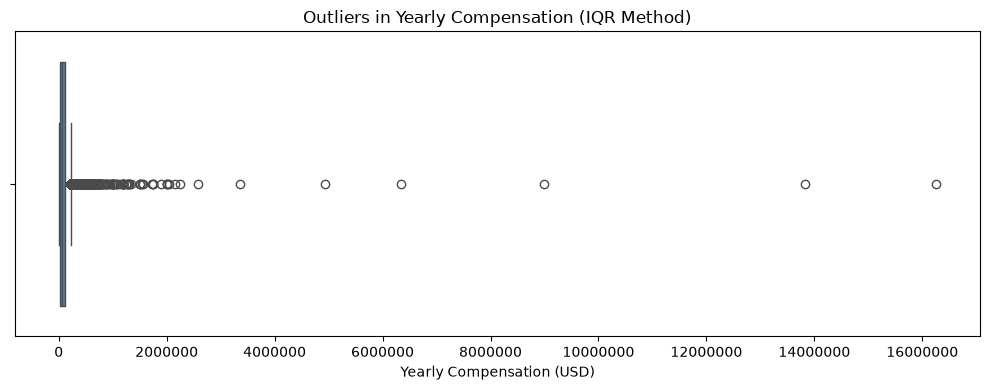

In [53]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["ConvertedCompYearly"], color="steelblue")

plt.title("Outliers in Yearly Compensation (IQR Method)")
plt.xlabel("Yearly Compensation (USD)")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

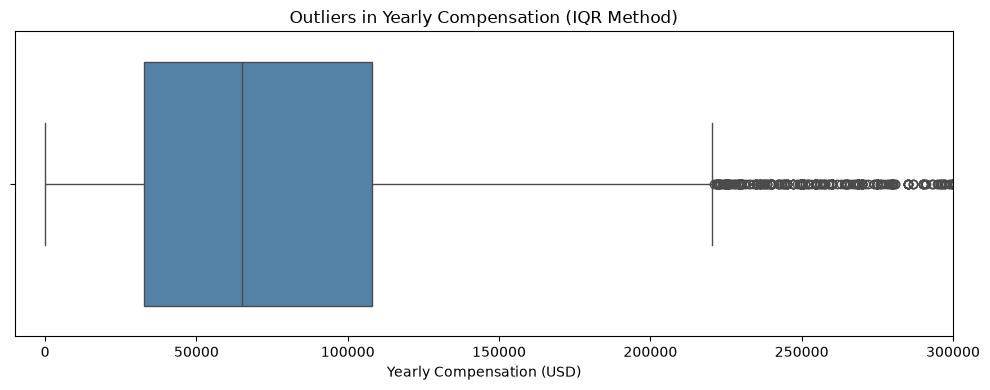

In [57]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["ConvertedCompYearly"], color="steelblue")

plt.title("Outliers in Yearly Compensation (IQR Method)")
plt.xlabel("Yearly Compensation (USD)")
plt.xlim(-10000, 300000)
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

<h3>Step 5: Remove Outliers and Create a New DataFrame</h3>


Remove outliers from the dataset.

- Create a new DataFrame excluding rows with outliers in `ConvertedCompYearly`.
- Validate the size of the new DataFrame.


In [60]:
df_no_outliers = df[
    (df["ConvertedCompYearly"] >= lower_bound) &
    (df["ConvertedCompYearly"] <= upper_bound)
].copy()
df_no_outliers.head(5)

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
72,73,I am a developer by profession,18-24 years old,"Employed, full-time;Student, full-time;Indepen...","Hybrid (some remote, some in-person)",Apples,Hobby;School or academic work;Professional dev...,"Secondary school (e.g. American high school, G...",On the job training;Other online resources (e....,Technical documentation;Blogs;Written Tutorial...,...,65.0,100.0,100.0,100.0,50.0,90.0,Too long,Easy,7322.0,10.0
374,375,"I am not primarily a developer, but I write co...",25-34 years old,"Employed, full-time","Hybrid (some remote, some in-person)",Apples,Hobby;School or academic work;Professional dev...,"Professional degree (JD, MD, Ph.D, Ed.D, etc.)",Books / Physical media;Colleague;On the job tr...,Written Tutorials;Stack Overflow;Written-based...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Neither easy nor difficult,30074.0,NaN
379,380,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Bootstrapping a business,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Other online resources ...,Technical documentation;Books;Social Media;Wri...,...,0.0,0.0,0.0,0.0,0.0,0.0,Too long,Difficult,91295.0,10.0
385,386,I am a developer by profession,35-44 years old,"Independent contractor, freelancer, or self-em...",Remote,Apples,Hobby,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;On the job training;Oth...,Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,53703.0,NaN
389,390,I am a developer by profession,25-34 years old,"Employed, full-time;Student, part-time",Remote,Apples,Hobby;School or academic work,Some college/university study without earning ...,Books / Physical media;Colleague;On the job tr...,Written Tutorials;Stack Overflow;Coding sessio...,...,20.0,30.0,5.0,20.0,10.0,5.0,Too long,Easy,110000.0,10.0


In [62]:
print("Original dataset size:", df.shape)
print("New dataset size:", df_no_outliers.shape)
print("Rows removed:", len(df) - len(df_no_outliers))

# Verify no outliers remain
remaining_outliers = df_no_outliers[
    (df_no_outliers["ConvertedCompYearly"] < lower_bound) |
    (df_no_outliers["ConvertedCompYearly"] > upper_bound)
]

print("Remaining outliers:", len(remaining_outliers))

Original dataset size: (65437, 114)
New dataset size: (22457, 114)
Rows removed: 42980
Remaining outliers: 0


<h3>Step 6: Correlation Analysis</h3>


Analyze the correlation between `Age` (transformed) and other numerical columns.

- Map the `Age` column to approximate numeric values.

- Compute correlations between `Age` and other numeric variables.

- Visualize the correlation matrix.


In [ ]:
# Map age categories to approximate numeric values
age_mapping = {
    "Under 18 years old": 16,
    "18-24 years old": 21,
    "25-34 years old": 30,
    "35-44 years old": 40,
    "45-54 years old": 50,
    "55-64 years old": 60,
    "65 years or older": 70
}

df["Age_numeric"] = df["Age"].map(age_mapping)

# Check the result
print(df[["Age", "Age_numeric"]].head())

                  Age  Age_numeric
0  Under 18 years old         16.0
1     35-44 years old         40.0
2     45-54 years old         50.0
3     18-24 years old         21.0
4     18-24 years old         21.0


In [69]:
# Select numeric columns
numeric_df = df.select_dtypes(include="number").copy()

# Add transformed Age if it isn't already included
numeric_df["Age_numeric"] = df["Age_numeric"]

# Calculate the correlation matrix
correlation_matrix = numeric_df.corr(method="pearson")
correlation_matrix

,ResponseId,CompTotal,WorkExp,JobSatPoints_1,JobSatPoints_4,JobSatPoints_5,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,ConvertedCompYearly,JobSat,Age_numeric
ResponseId,1.000000,-0.000000,0.011955,-0.002406,-0.015738,-0.014197,-0.001908,0.001843,-0.002968,0.001991,-0.005365,-0.005865,-0.008363,0.002425,-0.038245
CompTotal,-0.000000,0.000000,0.028766,-0.004891,-0.002719,-0.003033,-0.006311,-0.005893,-0.004585,-0.004494,-0.003198,-0.003045,0.080457,-0.015770,-0.002698
WorkExp,0.011955,0.028766,1.000000,-0.026490,-0.067241,-0.104525,-0.065352,-0.101461,-0.046958,-0.088090,-0.113707,-0.108279,0.154114,0.097322,0.848803
JobSatPoints_1,-0.002406,-0.004891,-0.026490,1.000000,0.445710,0.633765,0.618618,0.603157,0.627385,0.597527,0.585087,0.607792,0.020306,0.094068,-0.027675
JobSatPoints_4,-0.015738,-0.002719,-0.067241,0.445710,1.000000,0.526254,0.449400,0.459253,0.438763,0.472516,0.499387,0.528395,0.018197,0.029677,-0.076150
JobSatPoints_5,-0.014197,-0.003033,-0.104525,0.633765,0.526254,1.000000,0.613933,0.607949,0.630353,0.619644,0.643538,0.690993,-0.023281,0.049224,-0.101560
JobSatPoints_6,-0.001908,-0.006311,-0.065352,0.618618,0.449400,0.613933,1.000000,0.692166,0.645094,0.632211,0.592528,0.604585,-0.008518,0.051341,-0.050017
JobSatPoints_7,0.001843,-0.005893,-0.101461,0.603157,0.459253,0.607949,0.692166,1.000000,0.698240,0.659558,0.642905,0.618444,-0.036431,0.038339,-0.083232
JobSatPoints_8,-0.002968,-0.004585,-0.046958,0.627385,0.438763,0.630353,0.645094,0.698240,1.000000,0.655668,0.617320,0.625185,-0.011080,0.058258,-0.046204
JobSatPoints_9,0.001991,-0.004494,-0.088090,0.597527,0.472516,0.619644,0.632211,0.659558,0.655668,1.000000,0.663628,0.650676,-0.015867,0.039173,-0.081759


In [70]:
# View correlations specifically with Age
age_correlations = correlation_matrix["Age_numeric"].drop("Age_numeric")

print(age_correlations.sort_values(ascending=False))

WorkExp                0.848803
ConvertedCompYearly    0.122133
JobSat                 0.069818
CompTotal             -0.002698
JobSatPoints_1        -0.027675
ResponseId            -0.038245
JobSatPoints_8        -0.046204
JobSatPoints_6        -0.050017
JobSatPoints_4        -0.076150
JobSatPoints_9        -0.081759
JobSatPoints_7        -0.083232
JobSatPoints_5        -0.101560
JobSatPoints_11       -0.107170
JobSatPoints_10       -0.114571
Name: Age_numeric, dtype: float64


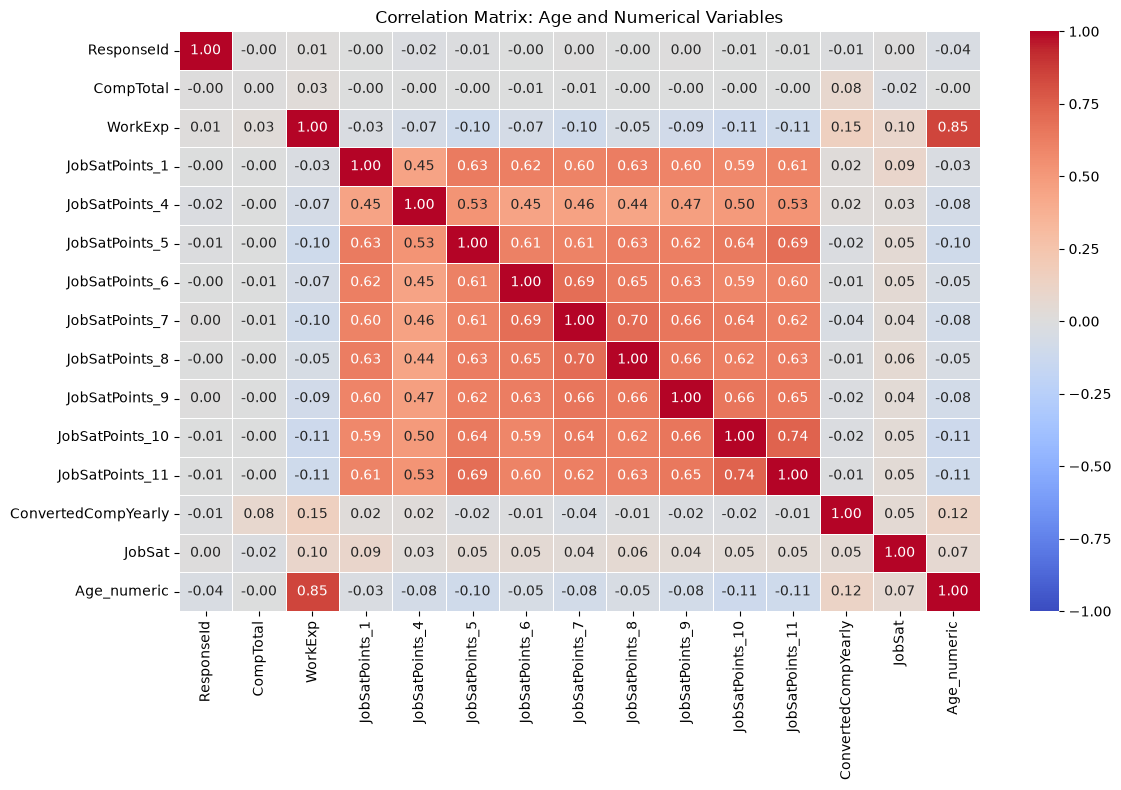

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix: Age and Numerical Variables")
plt.tight_layout()
plt.show()

<h3> Summary </h3>


In this lab, you developed essential skills in **Exploratory Data Analysis (EDA)** with a focus on outlier detection and removal. Specifically, you:


- Loaded and explored the dataset to understand its structure.

- Analyzed the distribution of respondents across industries.

- Identified and removed high compensation outliers using statistical thresholds and the Interquartile Range (IQR) method.

- Performed correlation analysis, including transforming the `Age` column into numeric values for better analysis.


<!--
## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|               
|2024-10-1|1.1|Madhusudan Moole|Reviewed and updated lab|                                                                                    
|2024-09-29|1.0|Raghul Ramesh|Created lab|
--!>


Copyright © IBM Corporation. All rights reserved.
